In [1]:
from google.colab import files

uploaded = files.upload()

Saving Toronto Island Ferry Tickets (1).csv to Toronto Island Ferry Tickets (1).csv


In [4]:
import pandas as pd

# Load dataset
df = pd.read_csv("Toronto Island Ferry Tickets (1).csv")

# Display first 5 rows
df.head()

df.head()

,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (261538, 4)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261538 entries, 0 to 261537
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   _id               261538 non-null  int64 
 1   Timestamp         261538 non-null  object
 2   Redemption Count  261538 non-null  int64 
 3   Sales Count       261538 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 8.0+ MB


In [7]:
df.describe()

,_id,Redemption Count,Sales Count
count,261538.000000,261538.000000,261538.000000
mean,130769.500000,48.885030,49.599106
std,75499.661689,104.549336,99.862285
min,1.000000,0.000000,0.000000
25%,65385.250000,3.000000,3.000000
50%,130769.500000,11.000000,13.000000
75%,196153.750000,40.000000,48.000000
max,261538.000000,7216.000000,7229.000000


In [8]:
df.isnull().sum()

,0
_id,0
Timestamp,0
Redemption Count,0
Sales Count,0


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
print(df.columns.tolist())

['_id', 'Timestamp', 'Redemption Count', 'Sales Count']


In [11]:
df.dtypes

,0
_id,int64
Timestamp,object
Redemption Count,int64
Sales Count,int64


In [13]:
# Create a copy of the original dataset
df_clean = df.copy()

In [14]:
# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", df_clean.shape[0])

Rows after removing duplicates: 261538


In [15]:
# Convert Timestamp column into datetime format
df_clean["Timestamp"] = pd.to_datetime(df_clean["Timestamp"])

print(df_clean["Timestamp"].dtype)

datetime64[ns]


In [16]:
# Remove rows with missing values
df_clean = df_clean.dropna()

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
_id                 0
Timestamp           0
Redemption Count    0
Sales Count         0
dtype: int64


In [17]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261538 entries, 0 to 261537
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   _id               261538 non-null  int64         
 1   Timestamp         261538 non-null  datetime64[ns]
 2   Redemption Count  261538 non-null  int64         
 3   Sales Count       261538 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 8.0 MB


In [18]:
# Calculate total ticket activity
df_clean["Total Activity"] = df_clean["Sales Count"] + df_clean["Redemption Count"]

df_clean.head()

,_id,Timestamp,Redemption Count,Sales Count,Total Activity
0,1,2025-12-21 22:30:00,14,16,30
1,2,2025-12-21 22:15:00,1,0,1
2,3,2025-12-21 22:00:00,2,0,2
3,4,2025-12-21 21:30:00,11,1,12
4,5,2025-12-21 21:15:00,10,0,10


In [20]:
# Extract hour from timestamp
df_clean["Hour"] = df_clean["Timestamp"].dt.hour

In [21]:
# Extract day of the week
df_clean["Day"] = df_clean["Timestamp"].dt.day_name()

In [22]:
# Extract month
df_clean["Month"] = df_clean["Timestamp"].dt.month

# Extract month name
df_clean["Month Name"] = df_clean["Timestamp"].dt.month_name()

In [23]:
# Extract year
df_clean["Year"] = df_clean["Timestamp"].dt.year

In [24]:
# Identify weekends
df_clean["Weekend"] = df_clean["Timestamp"].dt.dayofweek >= 5

df_clean[["Timestamp", "Total Activity", "Hour", "Day", "Month Name", "Year", "Weekend"]].head()

,Timestamp,Total Activity,Hour,Day,Month Name,Year,Weekend
0,2025-12-21 22:30:00,30,22,Sunday,December,2025,True
1,2025-12-21 22:15:00,1,22,Sunday,December,2025,True
2,2025-12-21 22:00:00,2,22,Sunday,December,2025,True
3,2025-12-21 21:30:00,12,21,Sunday,December,2025,True
4,2025-12-21 21:15:00,10,21,Sunday,December,2025,True


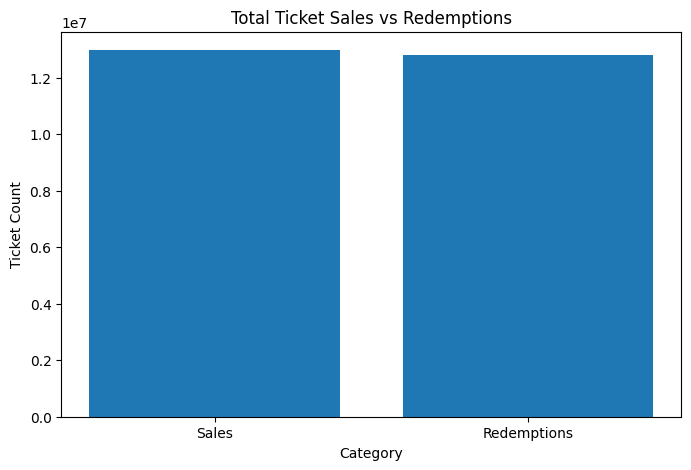

Total Sales: 12972051
Total Redemptions: 12785293


In [25]:
import matplotlib.pyplot as plt

# Calculate total sales and redemptions
total_sales = df_clean["Sales Count"].sum()
total_redemptions = df_clean["Redemption Count"].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(["Sales", "Redemptions"], [total_sales, total_redemptions])

plt.title("Total Ticket Sales vs Redemptions")
plt.ylabel("Ticket Count")
plt.xlabel("Category")

plt.show()

print("Total Sales:", total_sales)
print("Total Redemptions:", total_redemptions)

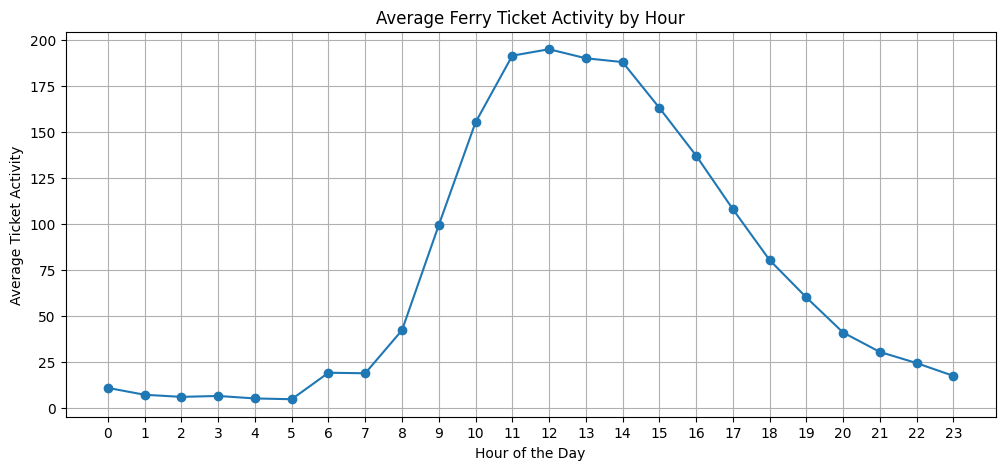

In [26]:
# Calculate average activity for each hour
hourly_activity = df_clean.groupby("Hour")["Total Activity"].mean()

# Plot hourly activity
plt.figure(figsize=(12, 5))
plt.plot(hourly_activity.index, hourly_activity.values, marker="o")

plt.title("Average Ferry Ticket Activity by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Ticket Activity")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [27]:
print("Busiest Hour:", hourly_activity.idxmax())
print("Highest Average Activity:", hourly_activity.max())

print("Lowest Activity Hour:", hourly_activity.idxmin())
print("Lowest Average Activity:", hourly_activity.min())

Busiest Hour: 12
Highest Average Activity: 194.75695597317218
Lowest Activity Hour: 5
Lowest Average Activity: 4.721411192214112


In [28]:
# Calculate average activity on weekdays and weekends
weekend_activity = df_clean.groupby("Weekend")["Total Activity"].mean()

print(weekend_activity)

Weekend
False     80.302653
True     143.944778
Name: Total Activity, dtype: float64


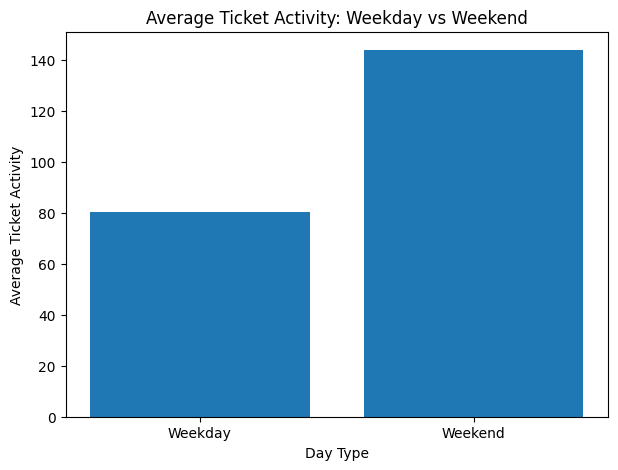

In [29]:
# Plot weekday vs weekend activity
plt.figure(figsize=(7, 5))
plt.bar(["Weekday", "Weekend"], weekend_activity.values)

plt.title("Average Ticket Activity: Weekday vs Weekend")
plt.ylabel("Average Ticket Activity")
plt.xlabel("Day Type")

plt.show()

In [30]:
print("Weekday Average Activity:", weekend_activity.loc[False])
print("Weekend Average Activity:", weekend_activity.loc[True])

Weekday Average Activity: 80.30265334196905
Weekend Average Activity: 143.94477829677317


In [31]:
# Calculate average activity by month
monthly_activity = df_clean.groupby("Month")["Total Activity"].mean()

print(monthly_activity)

Month
1      16.341753
2      19.256807
3      22.553366
4      42.069159
5      92.569821
6     144.662497
7     222.192852
8     244.809970
9     131.491209
10     56.966927
11     26.619704
12     18.221823
Name: Total Activity, dtype: float64


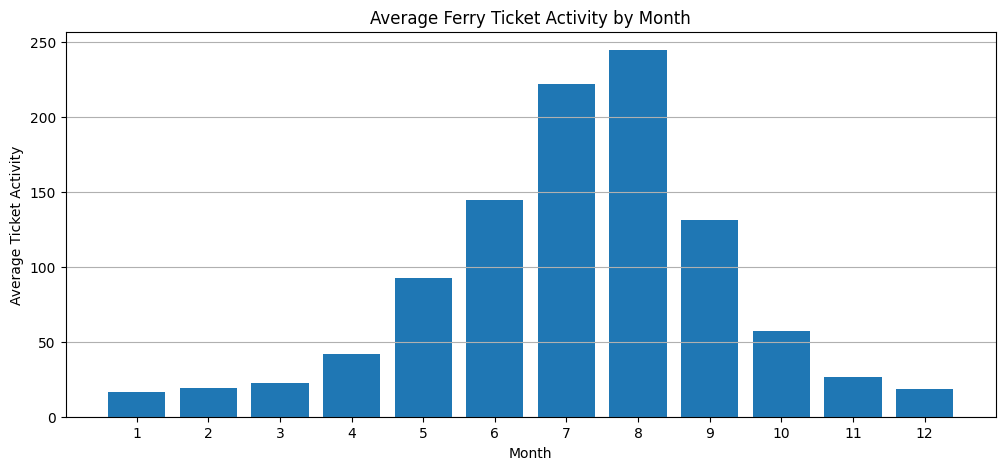

In [32]:
# Plot monthly activity
plt.figure(figsize=(12, 5))
plt.bar(monthly_activity.index, monthly_activity.values)

plt.title("Average Ferry Ticket Activity by Month")
plt.xlabel("Month")
plt.ylabel("Average Ticket Activity")
plt.xticks(range(1, 13))
plt.grid(axis="y")

plt.show()

In [33]:
print("Highest Activity Month:", monthly_activity.idxmax())
print("Highest Average Activity:", monthly_activity.max())

print("Lowest Activity Month:", monthly_activity.idxmin())
print("Lowest Average Activity:", monthly_activity.min())

Highest Activity Month: 8
Highest Average Activity: 244.8099698535745
Lowest Activity Month: 1
Lowest Average Activity: 16.341753084989282


In [34]:
# Calculate yearly total sales and redemptions
yearly_activity = df_clean.groupby("Year")[["Sales Count", "Redemption Count"]].sum()

yearly_activity

,Sales Count,Redemption Count
Year,,
2015,1189620,978707
2016,1518428,1425779
2017,682346,698861
2018,1463589,1493560
2019,1249725,1278505
2020,366606,374546
2021,782368,773040
2022,1346659,1349778
2023,1491473,1502883


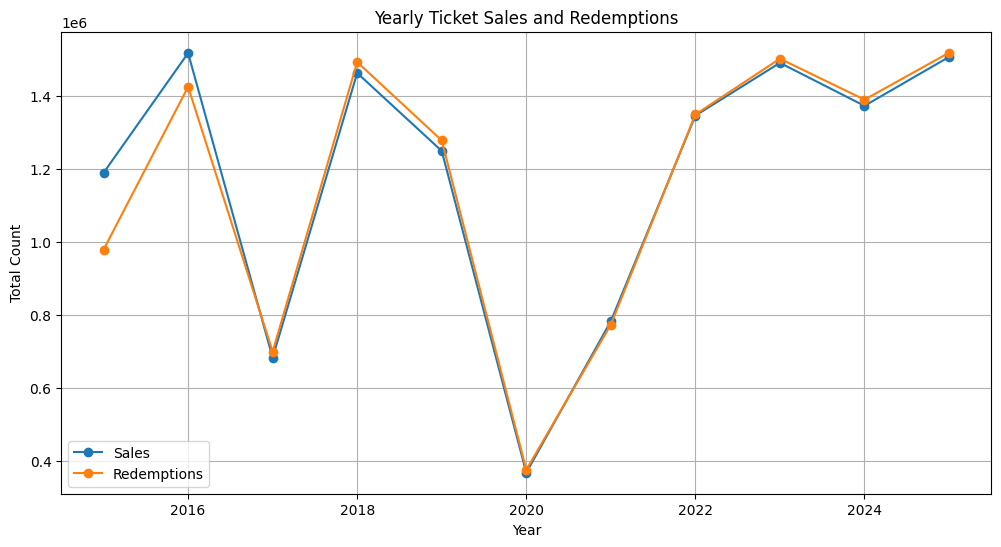

In [35]:
# Plot yearly ticket activity
plt.figure(figsize=(12, 6))

plt.plot(yearly_activity.index, yearly_activity["Sales Count"], marker="o", label="Sales")
plt.plot(yearly_activity.index, yearly_activity["Redemption Count"], marker="o", label="Redemptions")

plt.title("Yearly Ticket Sales and Redemptions")
plt.xlabel("Year")
plt.ylabel("Total Count")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
yearly_activity

,Sales Count,Redemption Count
Year,,
2015,1189620,978707
2016,1518428,1425779
2017,682346,698861
2018,1463589,1493560
2019,1249725,1278505
2020,366606,374546
2021,782368,773040
2022,1346659,1349778
2023,1491473,1502883


In [37]:
# Calculate average activity by day of the week
daily_activity = df_clean.groupby("Day")["Total Activity"].mean()

# Arrange days in correct order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_activity = daily_activity.reindex(day_order)

daily_activity

,Total Activity
Day,
Monday,90.467744
Tuesday,70.728466
Wednesday,75.629881
Thursday,75.685530
Friday,88.824019
Saturday,144.188042
Sunday,143.688936


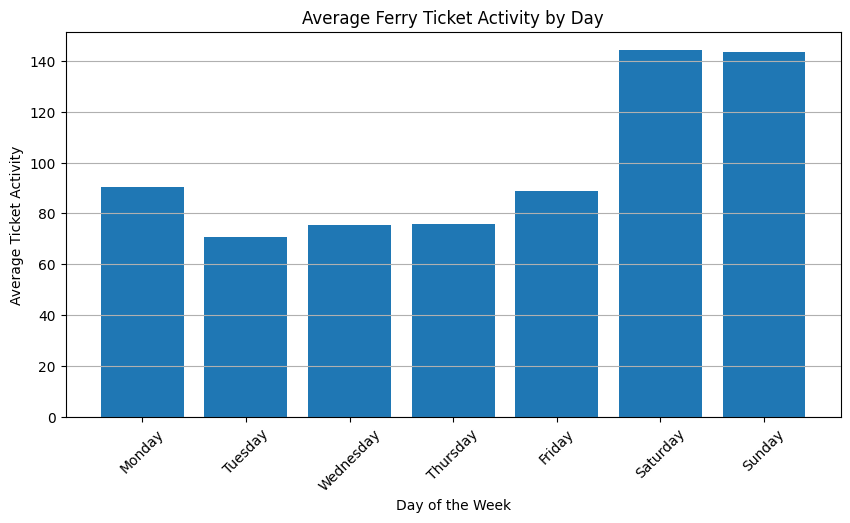

In [38]:
# Plot average daily activity
plt.figure(figsize=(10, 5))
plt.bar(daily_activity.index, daily_activity.values)

plt.title("Average Ferry Ticket Activity by Day")
plt.xlabel("Day of the Week")
plt.ylabel("Average Ticket Activity")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [39]:
print("Busiest Day:", daily_activity.idxmax())
print("Highest Average Activity:", daily_activity.max())

print("Lowest Activity Day:", daily_activity.idxmin())
print("Lowest Average Activity:", daily_activity.min())

Busiest Day: Saturday
Highest Average Activity: 144.18804177545692
Lowest Activity Day: Tuesday
Lowest Average Activity: 70.7284658442476


In [40]:
# Calculate monthly sales and redemptions
monthly_comparison = df_clean.groupby("Month")[["Sales Count", "Redemption Count"]].sum()

monthly_comparison

,Sales Count,Redemption Count
Month,,
1,130455,151620
2,146179,168535
3,201753,222769
4,401395,402168
5,1090751,1039836
6,1814395,1712766
7,3083858,2909572
8,3442762,3378623
9,1605867,1639862


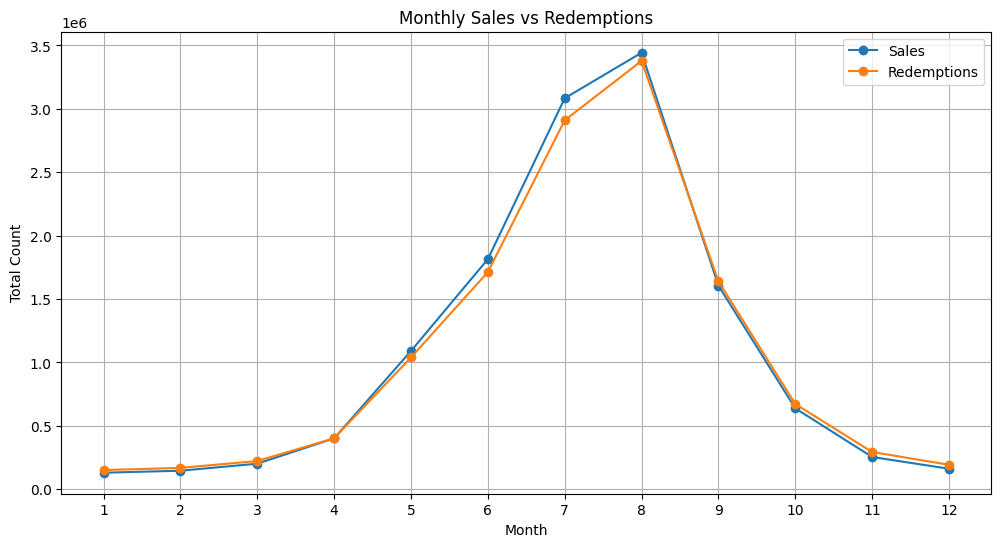

In [41]:
# Plot monthly sales and redemptions
plt.figure(figsize=(12, 6))

plt.plot(monthly_comparison.index, monthly_comparison["Sales Count"], marker="o", label="Sales")
plt.plot(monthly_comparison.index, monthly_comparison["Redemption Count"], marker="o", label="Redemptions")

plt.title("Monthly Sales vs Redemptions")
plt.xlabel("Month")
plt.ylabel("Total Count")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)

plt.show()

In [42]:
monthly_comparison

,Sales Count,Redemption Count
Month,,
1,130455,151620
2,146179,168535
3,201753,222769
4,401395,402168
5,1090751,1039836
6,1814395,1712766
7,3083858,2909572
8,3442762,3378623
9,1605867,1639862


In [43]:
# Calculate operational KPIs

total_intervals = len(df_clean)
average_activity = df_clean["Total Activity"].mean()
maximum_activity = df_clean["Total Activity"].max()

# Define high and low activity thresholds
high_threshold = df_clean["Total Activity"].quantile(0.90)
low_threshold = df_clean["Total Activity"].quantile(0.10)

# Count high and low activity intervals
high_activity_intervals = (df_clean["Total Activity"] >= high_threshold).sum()
low_activity_intervals = (df_clean["Total Activity"] <= low_threshold).sum()

# Calculate percentages
high_activity_percentage = (high_activity_intervals / total_intervals) * 100
low_activity_percentage = (low_activity_intervals / total_intervals) * 100

# Calculate operational variability
variability = df_clean["Total Activity"].std() / average_activity

# Display KPI results
print("Total Intervals:", total_intervals)
print("Average Activity:", round(average_activity, 2))
print("Maximum Activity:", maximum_activity)
print("High Activity Percentage:", round(high_activity_percentage, 2), "%")
print("Low Activity Percentage:", round(low_activity_percentage, 2), "%")
print("Operational Variability:", round(variability, 2))

Total Intervals: 261538
Average Activity: 98.48
Maximum Activity: 14445
High Activity Percentage: 10.03 %
Low Activity Percentage: 10.65 %
Operational Variability: 2.03


In [44]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Intervals",
        "Average Activity",
        "Maximum Activity",
        "High Activity Percentage",
        "Low Activity Percentage",
        "Operational Variability"
    ],
    "Value": [
        total_intervals,
        round(average_activity, 2),
        maximum_activity,
        round(high_activity_percentage, 2),
        round(low_activity_percentage, 2),
        round(variability, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Intervals,261538.00
1,Average Activity,98.48
2,Maximum Activity,14445.00
3,High Activity Percentage,10.03
4,Low Activity Percentage,10.65
5,Operational Variability,2.03


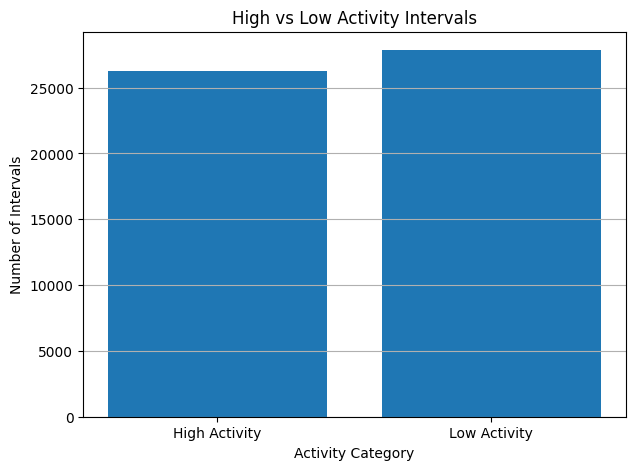

In [45]:
# Visualize high and low activity intervals

plt.figure(figsize=(7, 5))

plt.bar(
    ["High Activity", "Low Activity"],
    [high_activity_intervals, low_activity_intervals]
)

plt.title("High vs Low Activity Intervals")
plt.xlabel("Activity Category")
plt.ylabel("Number of Intervals")
plt.grid(axis="y")

plt.show()

In [46]:
print("High Activity Threshold (90th percentile):", round(high_threshold, 2))
print("Low Activity Threshold (10th percentile):", round(low_threshold, 2))

High Activity Threshold (90th percentile): 288.0
Low Activity Threshold (10th percentile): 2.0


In [47]:
# Prepare data for the heatmap

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heatmap_data = df_clean.pivot_table(
    values="Total Activity",
    index="Day",
    columns="Hour",
    aggfunc="mean"
)

heatmap_data = heatmap_data.reindex(day_order)

heatmap_data

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Day,,,,,,,,,,,,,,,,,,,,,
Monday,9.650155,6.034934,4.065068,4.422619,2.684211,4.076087,18.417342,15.795003,38.414103,91.008854,...,169.704926,144.744988,119.731572,99.267983,69.885811,51.653007,31.296156,26.512731,22.622331,13.137016
Tuesday,7.046358,9.121212,6.417021,4.577465,13.219048,4.475676,21.438710,15.554241,37.249292,80.920574,...,126.574551,107.171576,95.207521,74.719754,61.831238,45.152923,38.393923,23.450593,18.700656,12.303279
Wednesday,7.910859,5.040449,3.289575,3.178808,3.822581,2.782383,21.964040,18.486605,40.782345,93.478386,...,127.572318,110.882462,97.072510,77.118085,62.114943,52.287855,31.746774,26.986622,22.969488,12.644684
Thursday,8.777434,4.952830,8.448529,13.662857,5.807018,3.768362,19.406820,17.316659,36.699304,89.218705,...,128.866024,108.572089,94.698573,81.500467,65.120690,49.393316,34.735979,29.187363,21.716544,19.064861
Friday,9.202413,5.323475,6.979167,6.588235,5.740113,3.295276,16.135308,16.434314,41.559831,100.334933,...,157.298337,136.179393,118.677241,96.291822,80.481499,67.583164,47.555383,36.801498,29.754125,22.424225
Saturday,15.563231,9.618667,7.164815,4.520548,4.839130,6.555241,17.314932,24.800377,47.535914,117.586190,...,302.201878,268.348165,226.153417,172.856743,118.653700,83.775687,56.878392,40.607440,29.783569,21.402469
Sunday,14.204104,8.155050,5.083832,8.171171,3.112554,6.137584,18.443467,26.627767,55.430786,123.264246,...,294.667127,263.927940,209.302521,154.532250,103.681308,69.456224,45.276454,28.506367,24.275819,19.490610


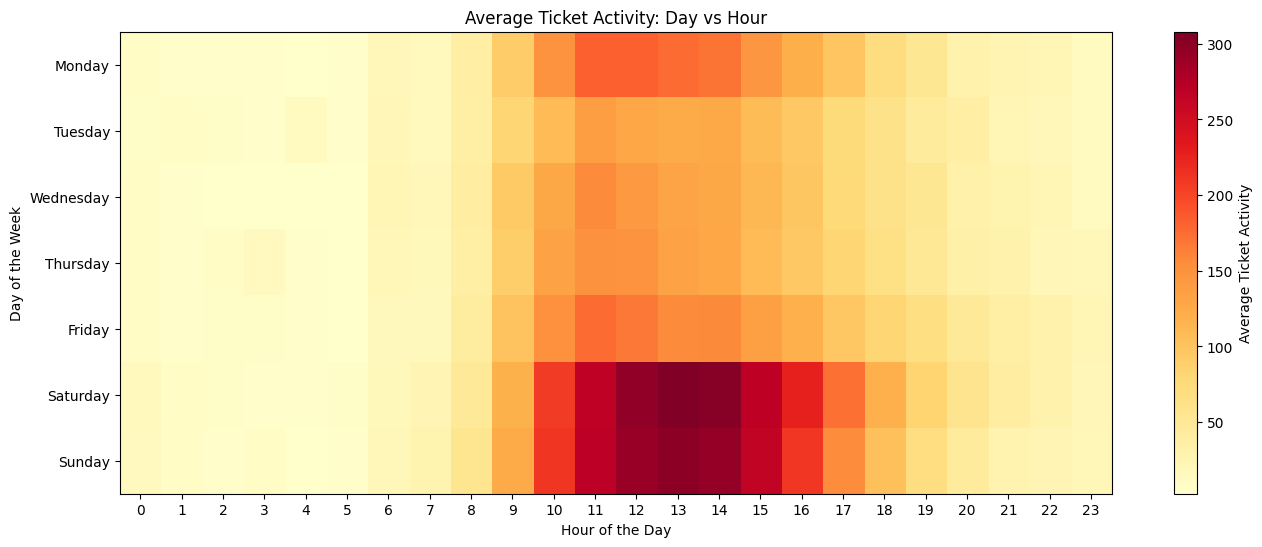

In [48]:
# Create Day vs Hour heatmap

plt.figure(figsize=(16, 6))

plt.imshow(heatmap_data, aspect="auto", cmap="YlOrRd")

plt.title("Average Ticket Activity: Day vs Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")

plt.xticks(range(24), range(24))
plt.yticks(range(7), day_order)

plt.colorbar(label="Average Ticket Activity")

plt.show()

In [49]:
# Calculate activity thresholds
q25 = df_clean["Total Activity"].quantile(0.25)
q75 = df_clean["Total Activity"].quantile(0.75)

print("25th Percentile:", q25)
print("75th Percentile:", q75)

25th Percentile: 7.0
75th Percentile: 88.0


In [50]:
# Classify activity levels

df_clean["Activity Level"] = "Moderate"

df_clean.loc[df_clean["Total Activity"] <= q25, "Activity Level"] = "Low"
df_clean.loc[df_clean["Total Activity"] >= q75, "Activity Level"] = "High"

df_clean[["Timestamp", "Total Activity", "Activity Level"]].head(10)

,Timestamp,Total Activity,Activity Level
0,2025-12-21 22:30:00,30,Moderate
1,2025-12-21 22:15:00,1,Low
2,2025-12-21 22:00:00,2,Low
3,2025-12-21 21:30:00,12,Moderate
4,2025-12-21 21:15:00,10,Moderate
5,2025-12-21 21:00:00,3,Low
6,2025-12-21 20:30:00,27,Moderate
7,2025-12-21 20:15:00,4,Low
8,2025-12-21 20:00:00,2,Low
9,2025-12-21 19:30:00,7,Low


In [51]:
# Count activity categories
activity_counts = df_clean["Activity Level"].value_counts()

print(activity_counts)

Activity Level
Moderate    128445
Low          67327
High         65766
Name: count, dtype: int64


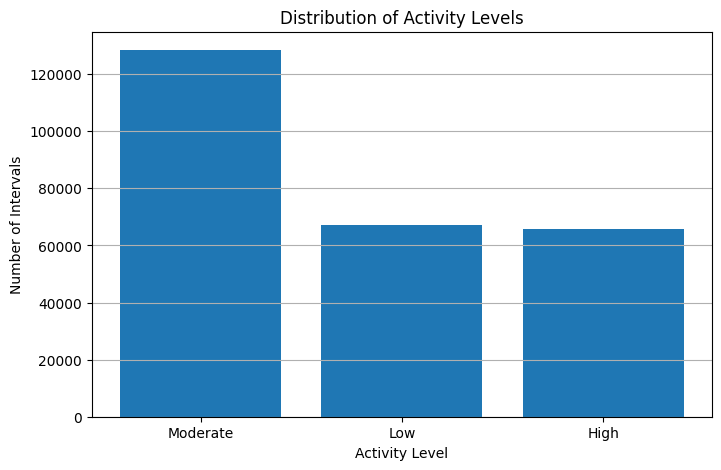

In [52]:
# Plot activity classification

plt.figure(figsize=(8, 5))
plt.bar(activity_counts.index, activity_counts.values)

plt.title("Distribution of Activity Levels")
plt.xlabel("Activity Level")
plt.ylabel("Number of Intervals")
plt.grid(axis="y")

plt.show()

In [53]:
# Find the top 10 intervals with the highest activity

peak_intervals = df_clean.sort_values(
    by="Total Activity",
    ascending=False
).head(10)

peak_intervals[["Timestamp", "Sales Count", "Redemption Count", "Total Activity"]]

,Timestamp,Sales Count,Redemption Count,Total Activity
61624,2023-08-15 20:15:00,7229,7216,14445
57273,2023-10-10 14:00:00,5518,5535,11053
40147,2024-06-19 19:00:00,5342,5341,10683
7768,2025-09-01 17:30:00,5218,5256,10474
36211,2024-08-05 22:00:00,4995,4973,9968
33540,2024-09-07 17:00:00,4974,4966,9940
5965,2025-09-24 22:30:00,4015,4020,8035
11651,2025-07-17 23:15:00,3701,3692,7393
65040,2023-07-05 21:15:00,3634,3602,7236
87888,2022-08-15 10:30:00,3408,3520,6928


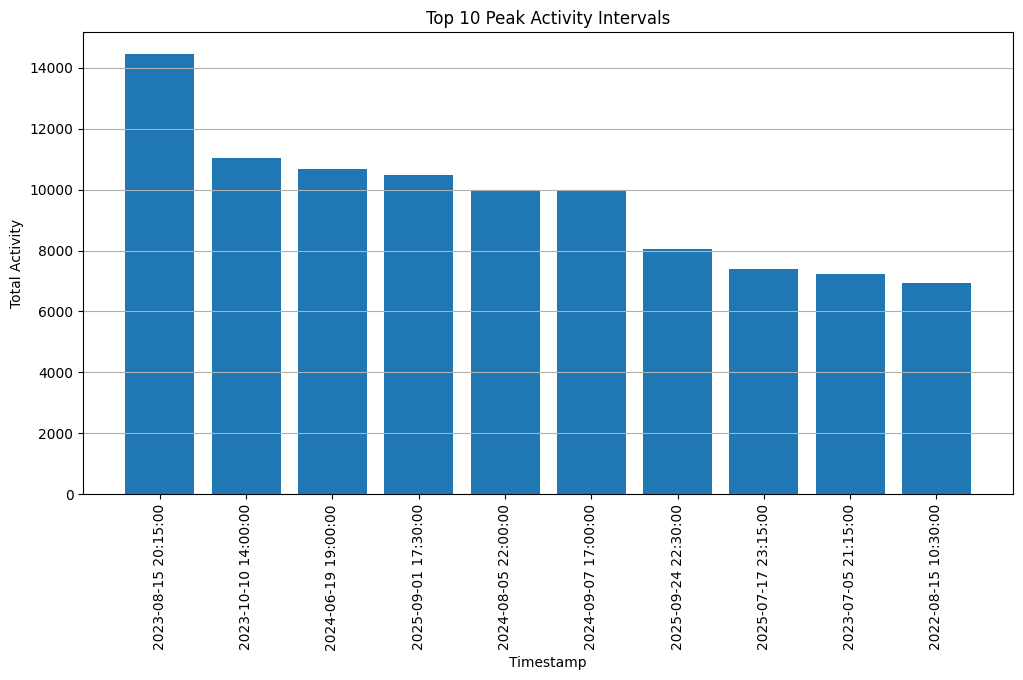

In [54]:
# Plot the top 10 peak intervals

plt.figure(figsize=(12, 6))

plt.bar(
    peak_intervals["Timestamp"].astype(str),
    peak_intervals["Total Activity"]
)

plt.title("Top 10 Peak Activity Intervals")
plt.xlabel("Timestamp")
plt.ylabel("Total Activity")
plt.xticks(rotation=90)
plt.grid(axis="y")

plt.show()

In [55]:
# Analyze the hours in which peak activity occurs

peak_hour_analysis = peak_intervals.groupby("Hour")["Total Activity"].count()

print("Peak intervals by hour:")
print(peak_hour_analysis)

Peak intervals by hour:
Hour
10    1
14    1
17    2
19    1
20    1
21    1
22    2
23    1
Name: Total Activity, dtype: int64


In [56]:
low_activity_data = df_clean[df_clean["Total Activity"] <= low_threshold]

low_activity_data[["Timestamp", "Sales Count", "Redemption Count", "Total Activity"]].head(10)

,Timestamp,Sales Count,Redemption Count,Total Activity
1,2025-12-21 22:15:00,0,1,1
2,2025-12-21 22:00:00,0,2,2
8,2025-12-21 20:00:00,2,0,2
52,2025-12-21 08:45:00,1,1,2
53,2025-12-21 08:30:00,1,1,2
54,2025-12-21 08:15:00,0,1,1
55,2025-12-21 08:00:00,1,1,2
56,2025-12-21 07:45:00,1,1,2
58,2025-12-21 07:15:00,2,0,2
61,2025-12-21 06:00:00,1,0,1


In [57]:
low_activity_count = len(low_activity_data)
low_activity_percentage = (low_activity_count / len(df_clean)) * 100

print("Low Activity Intervals:", low_activity_count)
print("Low Activity Percentage:", round(low_activity_percentage, 2), "%")
print("Low Activity Threshold:", round(low_threshold, 2))

Low Activity Intervals: 27852
Low Activity Percentage: 10.65 %
Low Activity Threshold: 2.0


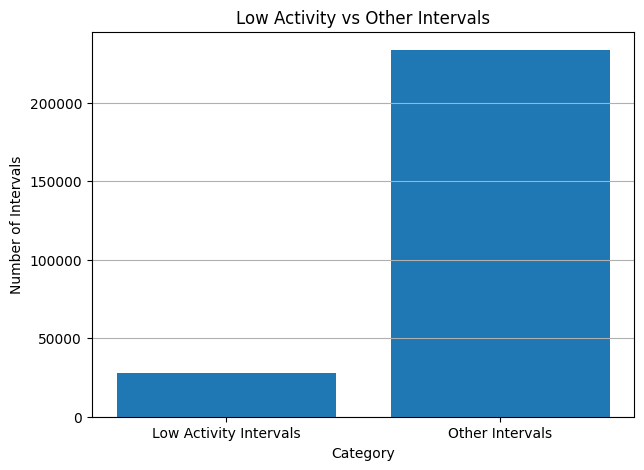

In [58]:
plt.figure(figsize=(7,5))

plt.bar(["Low Activity Intervals", "Other Intervals"],
        [low_activity_count, len(df_clean) - low_activity_count])

plt.title("Low Activity vs Other Intervals")
plt.xlabel("Category")
plt.ylabel("Number of Intervals")
plt.grid(axis="y")

plt.show()

In [59]:
print("===== BUSINESS INSIGHTS =====")

print("1. Busiest Hour:", hourly_activity.idxmax())
print("   Average Activity:", round(hourly_activity.max(), 2))

print("\n2. Busiest Day:", daily_activity.idxmax())
print("   Average Activity:", round(daily_activity.max(), 2))

print("\n3. Highest Activity Month:", monthly_activity.idxmax())
print("   Average Activity:", round(monthly_activity.max(), 2))

print("\n4. Weekend Average Activity:", round(weekend_activity.loc[True], 2))
print("   Weekday Average Activity:", round(weekend_activity.loc[False], 2))

print("\n5. Maximum Recorded Activity:", maximum_activity)

print("\n6. High Activity Intervals:", high_activity_intervals)
print("   Percentage:", round(high_activity_percentage, 2), "%")

print("\n7. Low Activity Intervals:", low_activity_count)
print("   Percentage:", round(low_activity_percentage, 2), "%")

===== BUSINESS INSIGHTS =====
1. Busiest Hour: 12
   Average Activity: 194.76

2. Busiest Day: Saturday
   Average Activity: 144.19

3. Highest Activity Month: 8
   Average Activity: 244.81

4. Weekend Average Activity: 143.94
   Weekday Average Activity: 80.3

5. Maximum Recorded Activity: 14445

6. High Activity Intervals: 26234
   Percentage: 10.03 %

7. Low Activity Intervals: 27852
   Percentage: 10.65 %


In [60]:
print("===== OPERATIONAL RECOMMENDATIONS =====")

print("\n1. Peak Hour Recommendation:")
print("Monitor ticket activity around hour", hourly_activity.idxmax(),
      "to prepare for periods of higher demand.")

print("\n2. Peak Day Recommendation:")
print("Pay additional attention to", daily_activity.idxmax(),
      "as it shows the highest average activity.")

print("\n3. Monthly Recommendation:")
print("Plan seasonal operational resources around month",
      monthly_activity.idxmax(),
      "which has the highest average ticket activity.")

print("\n4. High Activity Recommendation:")
print("Monitor high activity intervals to support better operational planning.")

print("\n5. Low Activity Recommendation:")
print("Review low activity periods to explore opportunities for efficient scheduling.")

print("\n6. Data Monitoring Recommendation:")
print("Continue monitoring sales and redemption data at 15-minute intervals.")

===== OPERATIONAL RECOMMENDATIONS =====

1. Peak Hour Recommendation:
Monitor ticket activity around hour 12 to prepare for periods of higher demand.

2. Peak Day Recommendation:
Pay additional attention to Saturday as it shows the highest average activity.

3. Monthly Recommendation:
Plan seasonal operational resources around month 8 which has the highest average ticket activity.

4. High Activity Recommendation:
Monitor high activity intervals to support better operational planning.

5. Low Activity Recommendation:
Review low activity periods to explore opportunities for efficient scheduling.

6. Data Monitoring Recommendation:
Continue monitoring sales and redemption data at 15-minute intervals.


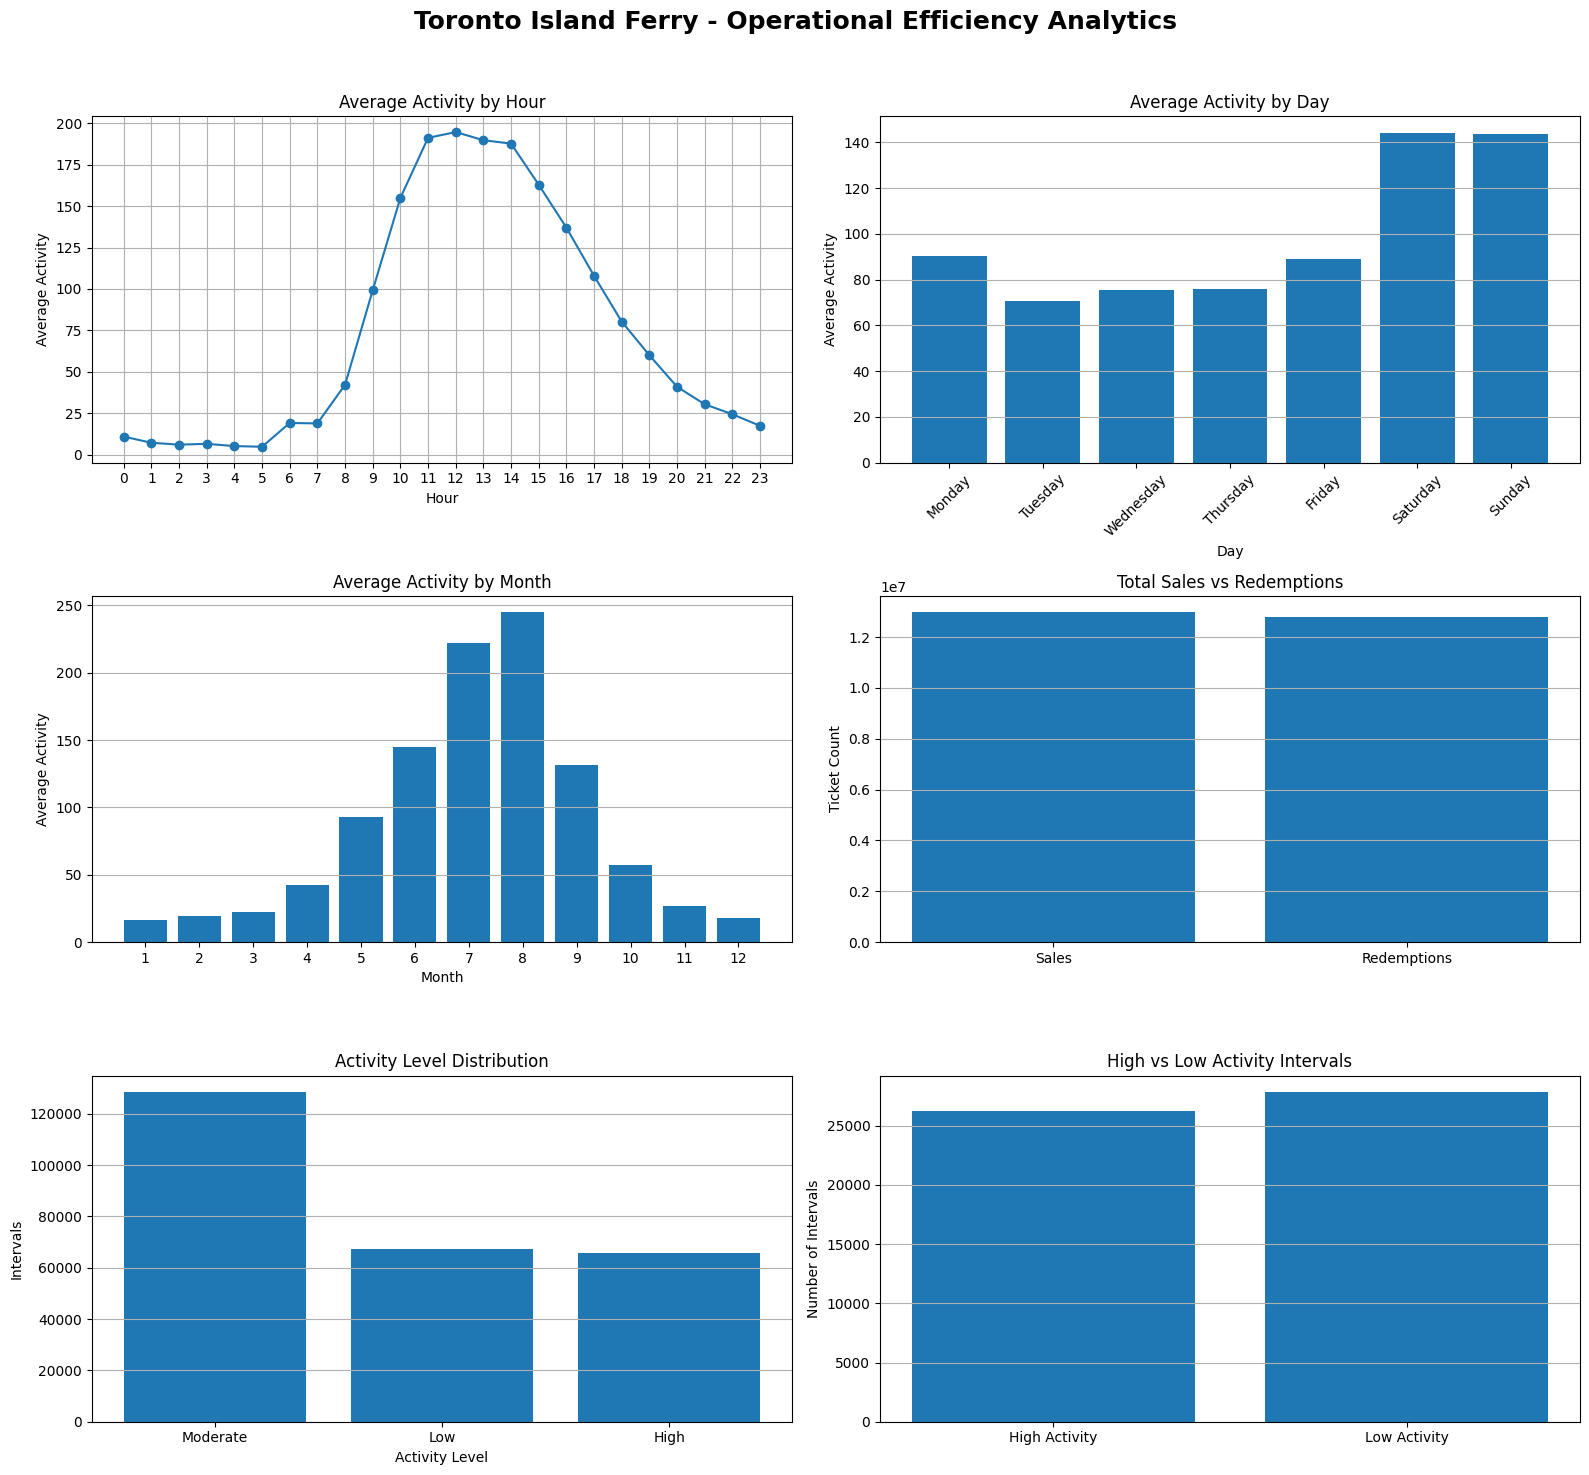

In [61]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
fig.suptitle("Toronto Island Ferry - Operational Efficiency Analytics",
             fontsize=18, fontweight="bold")

# 1. Hourly Activity
axes[0, 0].plot(hourly_activity.index, hourly_activity.values, marker="o")
axes[0, 0].set_title("Average Activity by Hour")
axes[0, 0].set_xlabel("Hour")
axes[0, 0].set_ylabel("Average Activity")
axes[0, 0].set_xticks(range(24))
axes[0, 0].grid(True)

# 2. Daily Activity
axes[0, 1].bar(daily_activity.index, daily_activity.values)
axes[0, 1].set_title("Average Activity by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Activity")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(axis="y")

# 3. Monthly Activity
axes[1, 0].bar(monthly_activity.index, monthly_activity.values)
axes[1, 0].set_title("Average Activity by Month")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Average Activity")
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].grid(axis="y")

# 4. Sales vs Redemptions
axes[1, 1].bar(["Sales", "Redemptions"],
                [total_sales, total_redemptions])
axes[1, 1].set_title("Total Sales vs Redemptions")
axes[1, 1].set_ylabel("Ticket Count")
axes[1, 1].grid(axis="y")

# 5. Activity Level Distribution
axes[2, 0].bar(activity_counts.index, activity_counts.values)
axes[2, 0].set_title("Activity Level Distribution")
axes[2, 0].set_xlabel("Activity Level")
axes[2, 0].set_ylabel("Intervals")
axes[2, 0].grid(axis="y")

# 6. High vs Low Activity
axes[2, 1].bar(["High Activity", "Low Activity"],
                [high_activity_intervals, low_activity_count])
axes[2, 1].set_title("High vs Low Activity Intervals")
axes[2, 1].set_ylabel("Number of Intervals")
axes[2, 1].grid(axis="y")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [62]:
df_clean.to_csv("Ferry_Analytics_Cleaned_Data.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [63]:
kpi_summary.to_csv("Ferry_Analytics_KPI_Summary.csv", index=False)

print("KPI summary exported successfully!")

KPI summary exported successfully!


In [64]:
hourly_activity.to_csv("Ferry_Analytics_Hourly_Analysis.csv")

print("Hourly analysis exported successfully!")

Hourly analysis exported successfully!


In [65]:
daily_activity.to_csv("Ferry_Analytics_Daily_Analysis.csv")

print("Daily analysis exported successfully!")

Daily analysis exported successfully!


In [66]:
monthly_activity.to_csv("Ferry_Analytics_Monthly_Analysis.csv")

print("Monthly analysis exported successfully!")

Monthly analysis exported successfully!


In [67]:
peak_intervals.to_csv("Ferry_Analytics_Peak_Intervals.csv", index=False)

print("Peak intervals exported successfully!")

Peak intervals exported successfully!


In [68]:
df_clean[["Timestamp", "Total Activity", "Activity Level"]].to_csv(
    "Ferry_Analytics_Activity_Classification.csv", index=False
)

print("Activity classification exported successfully!")

Activity classification exported successfully!


In [69]:
from google.colab import files

files.download("Ferry_Analytics_Cleaned_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
files.download("Ferry_Analytics_KPI_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
print("1. Busiest Hour:", hourly_activity.idxmax(),
      "| Average Activity:", round(hourly_activity.max(), 2))

print("2. Busiest Day:", daily_activity.idxmax(),
      "| Average Activity:", round(daily_activity.max(), 2))

print("3. Highest Activity Month:", monthly_activity.idxmax(),
      "| Average Activity:", round(monthly_activity.max(), 2))

print("4. Weekend Average Activity:", round(weekend_activity.loc[True], 2))
print("   Weekday Average Activity:", round(weekend_activity.loc[False], 2))

print("5. Highest Recorded Interval Activity:",
      df_clean["Total Activity"].max())


1. Busiest Hour: 12 | Average Activity: 194.76
2. Busiest Day: Saturday | Average Activity: 144.19
3. Highest Activity Month: 8 | Average Activity: 244.81
4. Weekend Average Activity: 143.94
   Weekday Average Activity: 80.3
5. Highest Recorded Interval Activity: 14445


In [72]:
df_clean.sort_values(
    by="Total Activity", ascending=False
).head(10)[
    ["Timestamp", "Sales Count", "Redemption Count", "Total Activity"]
]

,Timestamp,Sales Count,Redemption Count,Total Activity
61624,2023-08-15 20:15:00,7229,7216,14445
57273,2023-10-10 14:00:00,5518,5535,11053
40147,2024-06-19 19:00:00,5342,5341,10683
7768,2025-09-01 17:30:00,5218,5256,10474
36211,2024-08-05 22:00:00,4995,4973,9968
33540,2024-09-07 17:00:00,4974,4966,9940
5965,2025-09-24 22:30:00,4015,4020,8035
11651,2025-07-17 23:15:00,3701,3692,7393
65040,2023-07-05 21:15:00,3634,3602,7236
87888,2022-08-15 10:30:00,3408,3520,6928


In [73]:
# Generate project analysis CSV files

import pandas as pd
import zipfile

# Hourly analysis
hourly_export = df_clean.groupby("Hour").agg(
    Average_Sales=("Sales Count", "mean"),
    Average_Redemptions=("Redemption Count", "mean"),
    Average_Total_Activity=("Total Activity", "mean")
).reset_index()

# Daily analysis
daily_export = df_clean.groupby("Day").agg(
    Average_Sales=("Sales Count", "mean"),
    Average_Redemptions=("Redemption Count", "mean"),
    Average_Total_Activity=("Total Activity", "mean")
).reset_index()

# Monthly analysis
monthly_export = df_clean.groupby("Month").agg(
    Average_Sales=("Sales Count", "mean"),
    Average_Redemptions=("Redemption Count", "mean"),
    Average_Total_Activity=("Total Activity", "mean")
).reset_index()

# Peak activity intervals
peak_export = df_clean.nlargest(10, "Total Activity")

# Activity classification
q25 = df_clean["Total Activity"].quantile(0.25)
q75 = df_clean["Total Activity"].quantile(0.75)

df_clean["Activity Level"] = pd.cut(
    df_clean["Total Activity"],
    bins=[-float("inf"), q25, q75, float("inf")],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

classification_export = df_clean.copy()

# Save all files
hourly_export.to_csv("Hourly_Analysis.csv", index=False)
daily_export.to_csv("Daily_Analysis.csv", index=False)
monthly_export.to_csv("Monthly_Analysis.csv", index=False)
peak_export.to_csv("Peak_Intervals.csv", index=False)
classification_export.to_csv("Activity_Classification.csv", index=False)

print("All 5 analysis files generated successfully!")

All 5 analysis files generated successfully!


In [74]:
import zipfile
import os

files_to_zip = [
    "Hourly_Analysis.csv",
    "Daily_Analysis.csv",
    "Monthly_Analysis.csv",
    "Peak_Intervals.csv",
    "Activity_Classification.csv"
]

with zipfile.ZipFile("Ferry_Analysis_Files.zip", "w") as zipf:
    for file in files_to_zip:
        zipf.write(file)

from google.colab import files
files.download("Ferry_Analysis_Files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>